In [1]:
%pylab inline
import lsst.afw.image as afwImg

Populating the interactive namespace from numpy and matplotlib


In [33]:
# use the 5rd order warping version
tract='8522'
patch='1,1'
fname='/work/xiangchong.li/data/hsc_ssp/dr2/s18a/data/test/s18a_wide_revpsf/deepCoadd-results/HSC-I/%s/%s/calexp-HSC-I-%s-%s.fits'\
%(tract,patch,tract,patch)
exposure=afwImg.ExposureF.readFits(fname)
rescale_factor=exposure.getMetadata().get('variance_scale')

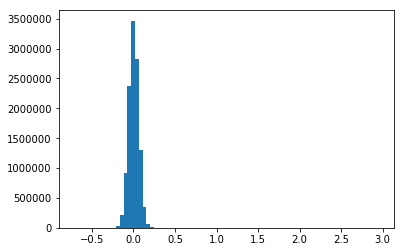

In [34]:
msk=exposure.getMask().getArray()[:,:]
img=exposure.getImage().getArray()[:,:]
var=exposure.getVariance().getArray()[:,:]
imgBlk=img[msk==0]
varBlk=var[msk==0]
# the histograme of blank pixels
histBlk1=plt.hist(imgBlk,bins=80)

variance of normalized blanck pixels: 0.995997
variance of rescaled normalized blanck pixels: 1.15527
rescale factor: 1.15991652042384


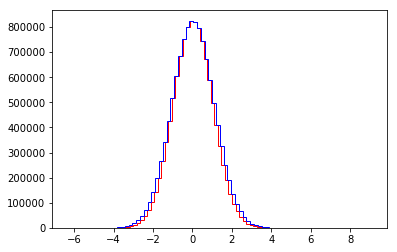

In [35]:
# the histograme of blank pixels normalized by sqrt(varBlk)
blkNorm=imgBlk/np.sqrt(varBlk)
blkNormRescale=imgBlk/np.sqrt(varBlk/rescale_factor)
histBlkNorm=plt.hist(blkNorm,bins=80,histtype='step',color='r')
histBlkNorm=plt.hist(blkNormRescale,bins=80,histtype='step',color='b')
print('variance of normalized blank pixels: %s' %np.var(blkNorm))
print('variance of rescaled normalized blank pixels: %s' %np.var(blkNormRescale))
print('rescale factor: %s' %rescale_factor)